# 01 · Guimarães: step-by-step stream analysis

**PA04 · Textile storage facility · T4 Humid vs Dry Regime**
**Author:** Khadija Belhamra (20230007), Student A · **Primary city:** Guimarães (City A)

**Question:** How do humid and dry regimes differ between candidate warehouse locations?

This notebook follows one procedure from loading the stream to the conclusions. Run `00_shared_protocol` first.

| Stage | Goal | Steps | Output |
|---|---|---|---|
| 1 | Load the stream and record its source | 1–2 | stream card |
| 2 | Inspect and describe the stream | 3–8 | tables, figures 1–5 |
| 3 | Measure the humid regime and interpret it for the warehouse | 9–13 | figures 6–8, profile tables |
| 4 | Run and evaluate the official prequential experiment | 14–20 | metrics, history, figures 9–12 |
| 5 | Diagnose errors and run additional experiments | 21–23 | error analysis, experiment tables |
| 6 | Conclude | 24 | conclusions for the report |

The comparison with Viana do Castelo is in `03_shared_comparison`.

## Stage 1: Load the stream and record its source

**What happens here:** Load the shared protocol, build this city's stream, and record exactly which data is being used.

**What to investigate:** Does the stream match the shared protocol, and which grid cell does the data really describe?

**Requirements covered:** Ch. 3.1 (common protocol), Ch. 12.1–12.4 (chronology, warm-up, frozen threshold), Ch. 15.2 (period and data snapshot).

### Step 1: Load the shared protocol and the stream

τ_H, the warm-up and the target all come from `data.prepare_frames`, the shared protocol. Nothing is set by hand here.

In [2]:
CITY_KEY = "guimaraes"

import sys
from pathlib import Path

# Make src/ importable whatever folder Jupyter was started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt

import plots
import profiling
from data import prepare_frames
from evaluate import evaluate_models, save_results
from features import make_streams
from models import make_models
from utils import load_config, output_dir

plots.set_style()
cfg = load_config()
prepared = prepare_frames(cfg)                 # shared protocol: same tau_H, warm-up and target as notebook 00
CITY = next(c for c in cfg["cities"] if c["key"] == CITY_KEY)
TAU_H = prepared["tau"]
df = prepared["frames"][CITY_KEY]              # this city's stream: timestamps, 4 variables, quality_flag, phase, y
print(f"{CITY['role']}: {CITY['name']}  |  {len(df)} hours  |  tau_H = {TAU_H:.2f} %")

City A: Guimaraes  |  26304 hours  |  tau_H = 82.00 %


In [3]:
import copy
import numpy as np
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from evaluate import run_prequential
from features import check_no_leakage
from plots import BLUE, ORANGE, AQUA, INK_2, GREY, MODEL_COLORS, HUMID, DRY

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
profile = profiling.profile_city(df, TAU_H, cfg)      # every descriptive table of this city, one call
pdf = profile["df"]                                   # stream + local_time, hour, month, year, season
EVAL = pdf["phase"] == "evaluation"

### Step 2: Record the grid point and period

Open-Meteo snaps the requested coordinates to its model grid, so this card records the grid point and period actually used (Ch. 15.2).

In [3]:
payload = prepared["payloads"][CITY_KEY]
card = pd.Series({
    "city / role": f"{CITY['name']} / {CITY['role']}",
    "requested point (lat, lon)": f"{CITY['latitude']:.3f}, {CITY['longitude']:.3f}",
    "grid point used (lat, lon)": f"{payload['latitude']:.3f}, {payload['longitude']:.3f}",
    "grid elevation (m)": payload["elevation"],
    "period": f"{pdf['timestamp'].min():%Y-%m-%d} to {pdf['timestamp'].max():%Y-%m-%d}",
    "hours": len(pdf),
    "warm-up (learn only)": f"{(~EVAL).sum()} h, until {prepared['warmup_end']:%Y-%m-%d %H:%M}",
    "evaluation (prequential)": f"{EVAL.sum()} h, from {prepared['evaluation_start']:%Y-%m-%d}",
    "tau_H (pooled warm-up, frozen)": f"{TAU_H:.1f} %",
}, name="value")
card.to_frame()

,value
city / role,Guimaraes / City A
"requested point (lat, lon)","41.429, -8.318"
"grid point used (lat, lon)","41.441, -8.288"
grid elevation (m),170.0000
period,2023-01-01 to 2025-12-31
hours,26304
warm-up (learn only),"8760 h, until 2023-12-31 23:00"
evaluation (prequential),"17544 h, from 2024-01-01"
"tau_H (pooled warm-up, frozen)",82.0 %


The grid point used for Guimarães is about 2.9 km northeast of the requested point, at an elevation of 170 m.

- **Elevation:** 170 m is broadly in line with the town itself, so the cell represents general conditions in Guimarães reasonably well. The 155 m gap to Viana (15 m) also fits the real inland vs. coastal contrast.
- **Valley vs. town:** A warehouse would likely sit in an industrial area on lower valley ground (e.g. along the Ave valley) rather than in the town centre. Valley floors tend to trap cool, moist air at night, causing more fog, higher night-time humidity and more hours above τ_H than the grid cell shows.
- **Resolution:** A single grid cell smooths out local terrain, so small-scale effects like valley humidity or nearby hills aren't captured.

> **Conclusion:** The cell is representative of Guimarães at town scale, but it may slightly **underestimate humid hours** at a low-lying valley site. That makes the dry-regime results for Guimarães a somewhat optimistic estimate for an actual warehouse location.

## Stage 2: Inspect and describe the stream

**What happens here:** Characterise the stream before any modelling: its quality, statistics, evolution over time, class balance, short-term behaviour and extremes.

**What to investigate:** Can the data be trusted, how does humidity behave across seasons and years, is the warm-up comparable with the evaluation period, and which metrics does the class balance allow? Extreme values are inspected and explained, never removed.

**Requirements covered:** Ch. 9 items 1–6, Ch. 11.1 (class balance), Ch. 18 (no undocumented deletion).

### Step 3: Check data quality

Check for missing and invalid values (Ch. 9 item 1). Extreme is not the same as erroneous, so nothing is deleted.

In [4]:
display(profile["quality"])
profile["special"].to_frame("value")

,missing,flagged invalid,longest constant run (h),distinct values,unit
Temperature,0,0,5,391,°C
Relative humidity,0,0,14,87,%
Precipitation,0,0,540,101,mm
Wind speed,0,0,5,371,km/h


,value
"RH = 100 % (saturation), hours",496.0000
"RH = 100 %, share",0.0189
"wind = 0 km/h (calm), hours",11.0000
"precipitation > 0 mm, hours",6036.0000
"precipitation > 0 mm, share",0.2295


**Summary:** All 26,304 hours for Guimarães are complete, with 0 missing and 0 flagged invalid values in all four variables. No data was removed, because none of the remaining patterns points to an error.

**Why nothing was removed:**
- **Constant runs are short** for temperature and wind (max 5 h), which is normal for hourly data.
- **RH's longest constant run is 14 h.** RH has only 87 distinct values, which suggests coarse resolution, so repeated values over several hours are expected during stable humid conditions.
- **Precipitation's 540 h constant run** is most plausibly a dry spell (about 22 days), since only 23% of hours (6,036) have any rain at all. Long runs of zero are normal for this variable.
- **RH = 100% in 496 h (1.9%)** is a small share, consistent with occasional saturation events rather than a capped or faulty sensor.
- **Calm wind in only 11 h** is rare enough to be realistic, not a sign of a stuck value.

Removing any of these would delete plausible weather and could bias the humid/dry classes.

### Step 4: Compute descriptive statistics

Descriptive statistics of the main variables (Ch. 9 item 2): whole period, warm-up vs evaluation, and seasons (DJF = winter, MAM = spring, JJA = summer, SON = autumn).

In [5]:
display(profile["describe"])
display(profile["by_phase"])
profile["by_season"]

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
Temperature (°C),26304.0000,15.6038,6.5583,-1.5000,2.6000,5.4000,11.1000,15.1000,19.5000,27.5000,32.9000,39.8000,0.4137
Relative humidity (%),26304.0000,76.9514,18.2794,13.0000,30.0000,42.0000,64.0000,82.0000,93.0000,98.0000,100.0000,100.0000,-0.7613
Precipitation (mm),26304.0000,0.2079,0.7718,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.2000,3.9000,17.7000,6.6297
Wind speed (km/h),26304.0000,9.6913,5.9435,0.0000,0.8000,2.2000,5.2000,8.6000,13.0000,20.9000,27.5000,44.0000,1.0126


phase                     warm-up  evaluation
Temperature       mean    15.4856     15.6628
                  std      6.3828      6.6437
                  median  15.4000     14.9000
Relative humidity mean    77.6537     76.6007
                  std     17.5966     18.6015
                  median  82.0000     81.0000
Precipitation     mean     0.2146      0.2046
                  std      0.8250      0.7439
                  median   0.0000      0.0000
Wind speed        mean    10.0270      9.5237
                  std      5.9465      5.9350
                  median   8.9000      8.5000

,Temperature,Relative humidity,Precipitation,Wind speed,humid share (y=1)
season,,,,,
DJF,9.7456,81.8152,0.2694,10.4200,0.5939
MAM,14.1247,76.4770,0.2064,10.3001,0.4826
JJA,22.0439,70.3222,0.0541,8.0822,0.3665
SON,16.4025,79.3036,0.3038,9.9793,0.5602


For a textile store, relative humidity is the key variable, and the outputs show it is both high and highly variable in Guimarães.

**Variables**
- **Relative humidity:** Mean 77.0%, median 82%, std 18.3, with a long tail down to 13% (negative skew). Humid conditions are the norm, and dry hours come as shorter drops below that level. This is the variable that defines the humid/dry regimes.
- **Temperature:** Wide spread (std 6.6 °C, P5–P95 5.4–27.5 °C, range −1.5 to 39.8 °C). It is relevant because seasons with higher mean temperature have lower mean RH.
- **Precipitation:** Usually zero (median 0, P75 0) but strongly skewed (skew 6.6, max 17.7 mm). It is rare and intermittent, so it is a weak standalone indicator.
- **Wind:** Moderate (mean 9.7 km/h, P95 20.9 km/h). It varies little across seasons and is the lowest in summer.

**Seasons**
- **Winter (DJF)** and **autumn (SON)** are the most critical, with the highest mean RH (81.8% and 79.3%), humid shares of 59% and 56%, and the most precipitation.
- **Summer (JJA)** is the driest, with mean RH of 70.3%, only 37% humid hours and very little rain.
- **Spring (MAM)** is in between and close to balanced (48% humid).

**Warm-up vs. evaluation:** The two phases are very similar (RH mean 77.7 vs. 76.6%, median 82 vs. 81%, temperature 15.5 vs. 15.7 °C). The evaluation period is slightly drier and more variable, but it isn't a different regime.

> **Takeaway:** Humidity control matters most from autumn to winter. Summer is the period with the most dry hours.

### Step 5: Plot the temporal evolution

Temporal evolution (Ch. 9 item 3): daily means over the three years, then hourly RH by calendar month against τ_H.

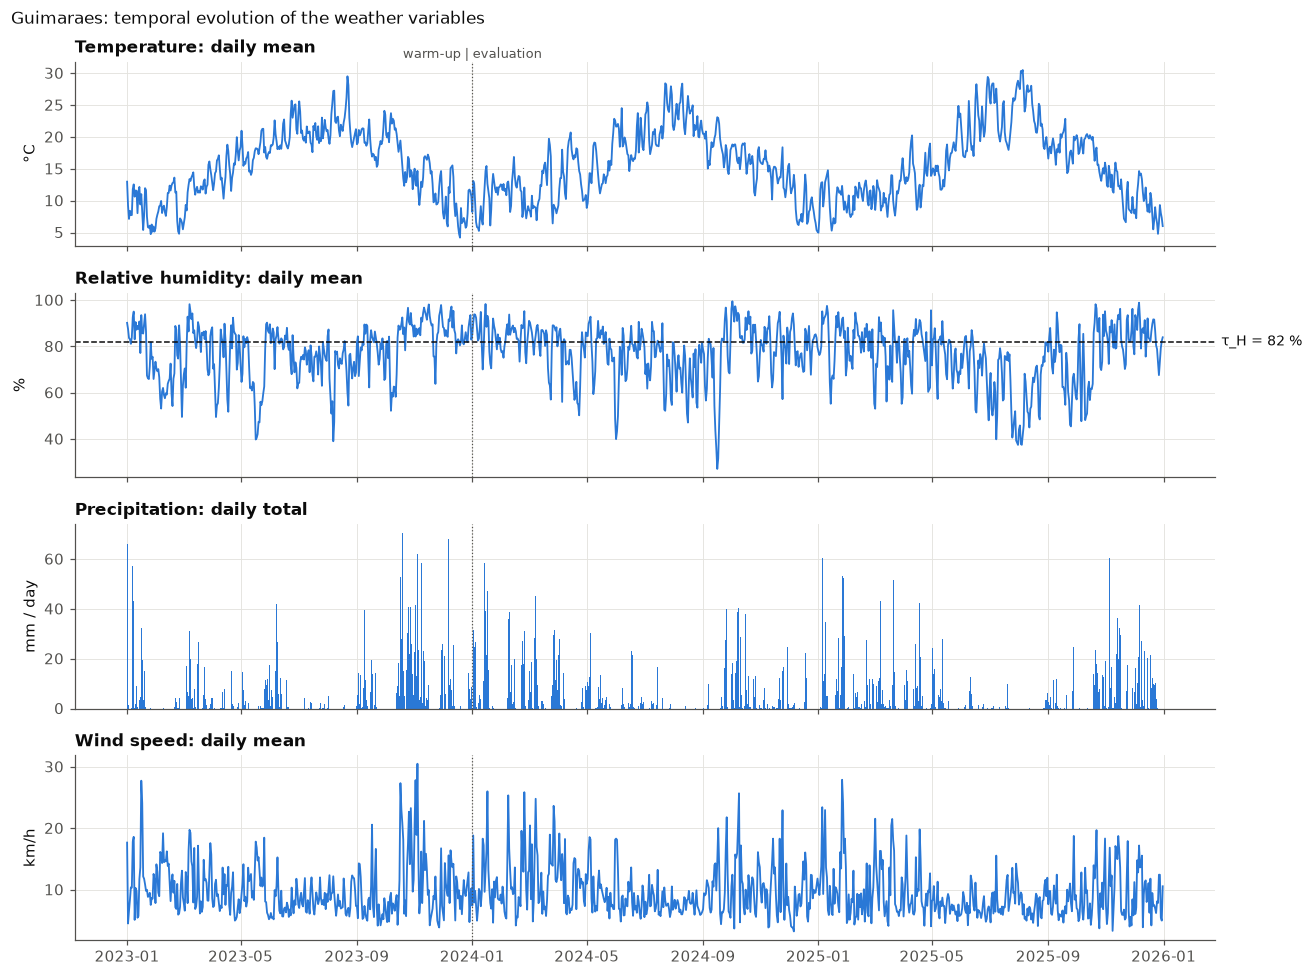

In [6]:
fig = plots.daily_evolution(profile, prepared, cfg, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_01_daily_evolution")
plt.show()

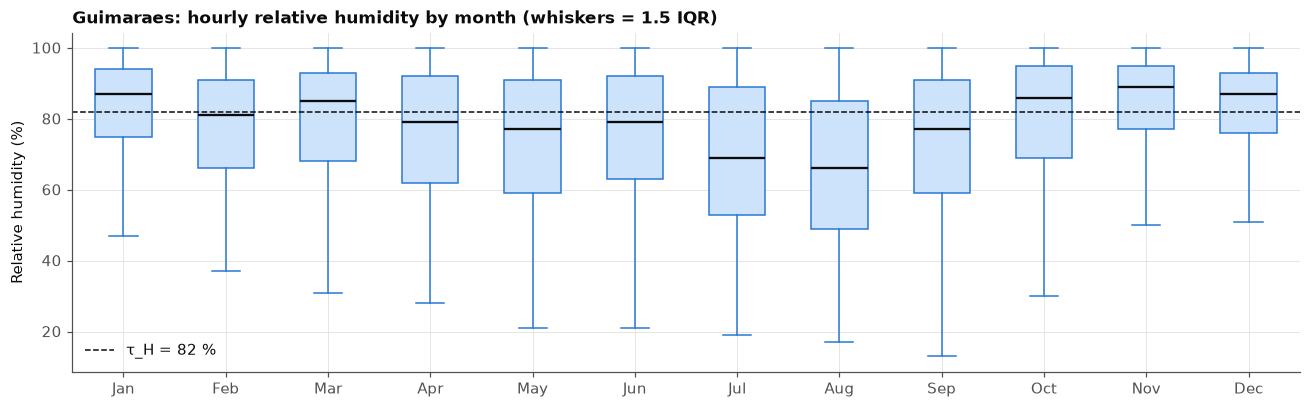

In [7]:
fig = plots.rh_by_month(profile, prepared, cfg, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_02_rh_by_month")
plt.show()

Guimarães shows a clear annual cycle, with humidity running opposite to temperature.

**Main patterns**
- **Seasonal cycle:** Temperature peaks in summer and drops in winter every year. Daily mean RH does the opposite, staying mostly above τ_H from autumn to winter and dropping below it in summer.
- **Monthly RH:** Medians are highest in Nov–Jan (87–89%), followed by Oct (86%) and Mar (85%), and lowest in Jul (69%) and Aug (66%).
- **Spread within months:** Winter months have narrow boxes that sit mostly above τ_H, so they are consistently humid. Summer months have wide boxes: in August, half of the hours fall between 49% and 85%, with the lower whisker near 17%. Summer has mostly dry hours but also many humid ones.
- **Precipitation** comes in bursts, mainly from autumn to winter, and is almost absent in summer. Its wettest periods line up with the high-RH periods.
- **Wind** is more variable from autumn to winter and calmer in summer.
- **Year-to-year differences:** Summer 2025 stands out with the highest daily temperatures and the deepest RH dips, so no two years are identical.
- **Short-term variability:** Daily RH regularly swings by tens of points within days, crossing τ_H often.

**Why it matters for environmental control**
- **Nov–Jan (and Oct, Mar):** Humid conditions are persistent, so continuous dehumidification is needed.
- **Summer:** Mostly dry, but with a wide range and frequent switches between regimes. Control needs to respond to short humid episodes rather than run on a fixed setting.
- **Frequent crossings of τ_H** mean that predicting the next hours' regime has practical value for planning control in advance.
- **Year-to-year differences** mean that control planning shouldn't rely on one "typical" year.

### Step 6: Inspect the class distribution

Target frequency and class distribution (Ch. 9 item 4, Ch. 11.1). T4: y = 1 (humid) if RH_t ≥ τ_H = 82 %.

In [8]:
display(profile["class_by_phase"])
display(profile["class_by_year"])
profile["class_by_season"]

,hours,humid_hours,humid_share,dry_share
phase,,,,
warm-up,8760,4475.0000,0.5108,0.4892
evaluation,17544,8683.0000,0.4949,0.5051


,hours,humid_hours,humid_share,dry_share
year,,,,
2023,8760,4475.0000,0.5108,0.4892
2024,8784,4560.0000,0.5191,0.4809
2025,8760,4123.0000,0.4707,0.5293


,hours,humid_hours,humid_share,dry_share
season,,,,
DJF,6504,3863.0000,0.5939,0.4061
MAM,6621,3195.0000,0.4826,0.5174
JJA,6624,2428.0000,0.3665,0.6335
SON,6555,3672.0000,0.5602,0.4398


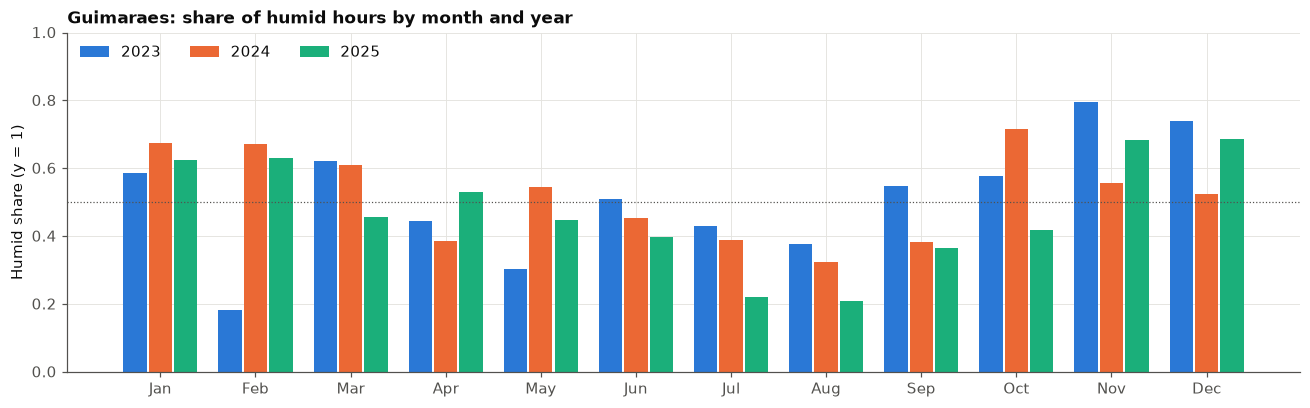

In [9]:
fig = plots.humid_share_month_year(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_03_humid_share_month_year")
plt.show()

Overall, the humid and dry classes in Guimarães are almost balanced, but the balance shifts clearly by season and from year to year.

**Class balance**
- **Phases:** 51.1% humid in the warm-up and 49.5% in evaluation, so very close to 50/50.
- **Years:** 2023 51.1%, 2024 51.9%, 2025 47.1%. 2025 was the driest year.
- **Seasons:** winter 59.4%, autumn 56.0%, spring 48.3%, summer 36.7% humid.
- **Months:** The same month can differ a lot between years. For example, February 2023 was mostly dry but February 2024 and 2025 were mostly humid, and July–August 2025 had far fewer humid hours than the previous years.

**What it means for metrics**
- Over the whole evaluation period, the split implies that always predicting "dry" would reach 50.5% **Accuracy**. Accuracy is a fair headline metric, but only meaningful well above that level and compared with the **persistence rule**.
- **Macro-F1** is needed alongside it because the classes are unbalanced by season: in summer a model can look accurate just by predicting "dry".
- **Precision and Recall** for the humid class, plus the **confusion matrix**, show whether humid hours are missed, which is the costly error for a textile store.

**When the store is most exposed**
- **Winter and autumn** have the most humid hours, with November–January the highest months in the chart.
- **Summer** is the safest period, though not humidity-free.
- Because exposure varies from year to year (e.g. 2024 vs. 2025), planning shouldn't rely on a single year.

### Step 7: Analyse rolling windows

Rolling behaviour (Ch. 9 item 5), using the 6 h and 24 h windows of Representation B plus a 7-day humid share. The figures show three years, then two weeks in detail.

In [10]:
profile["rolling_by_season"]

,rh_std_6h,rh_std_24h,humid_share_7d
season,,,
DJF,3.7639,9.6184,0.6548
MAM,5.3944,13.6678,0.4821
JJA,6.6558,16.2142,0.3810
SON,4.3818,11.5626,0.5714


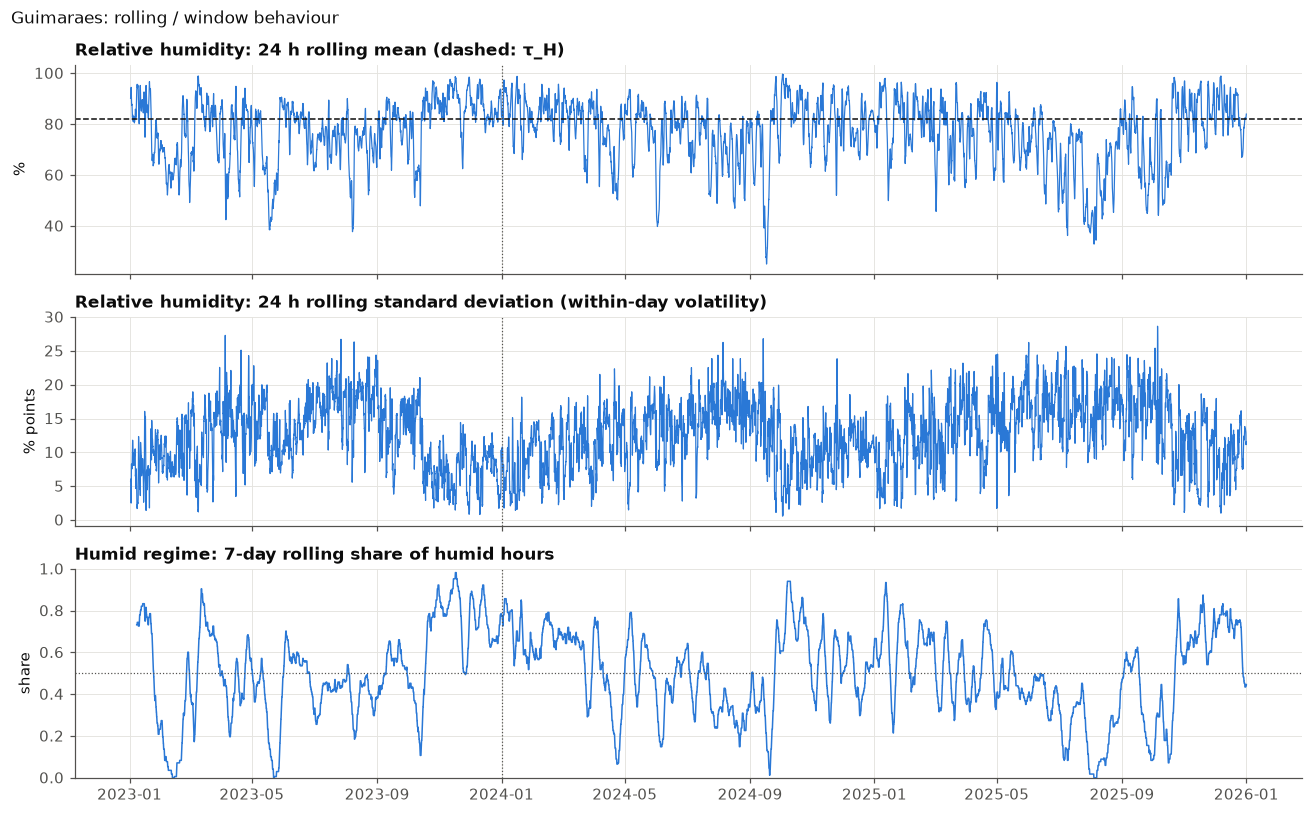

In [11]:
fig = plots.rolling_overview(profile, prepared, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_04_rolling_overview")
plt.show()

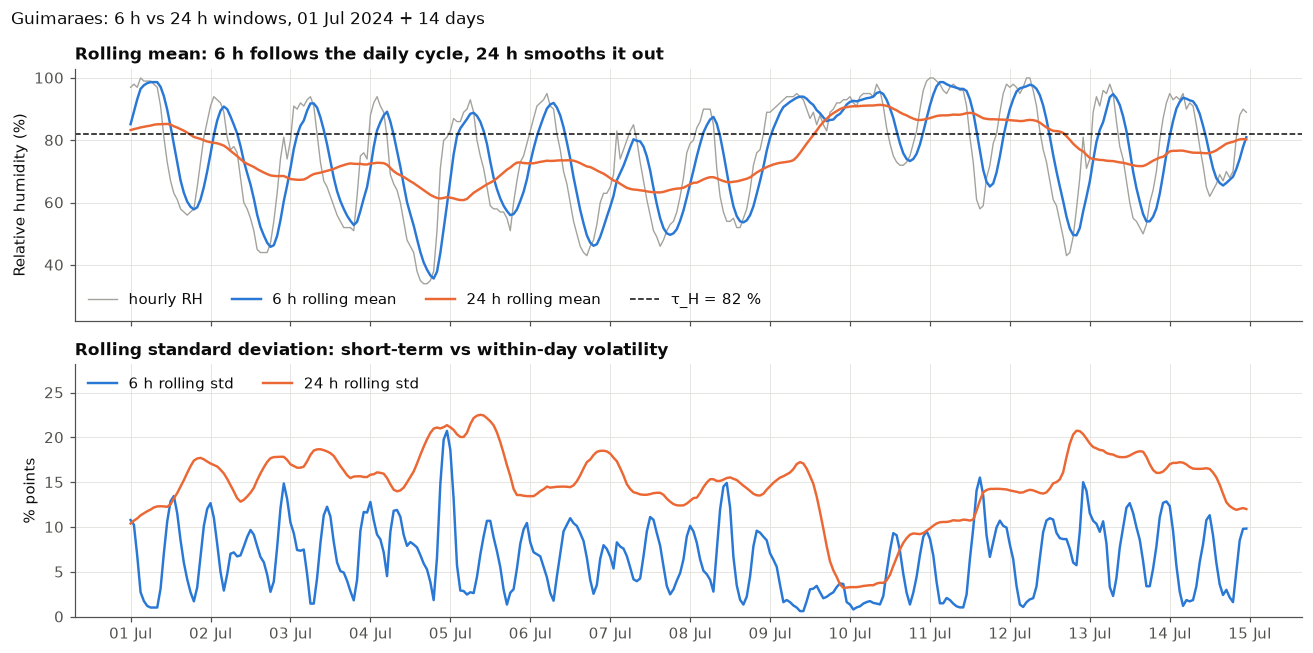

In [12]:
ZOOM_START = "2024-07-01"     # same excerpt in both city notebooks, so Figure 5 is comparable
fig = plots.rolling_zoom(profile, prepared, cfg, CITY["name"], start=ZOOM_START, days=14)
plots.save(fig, cfg, f"{CITY_KEY}_05_rolling_zoom")
plt.show()

The 6 h and 24 h windows capture humidity behaviour at two different time scales.

**What each window shows**
- **6 h window:** Follows the daily cycle. In the July 2024 example, the 6 h mean rises and falls with hourly RH every day, crossing τ_H. The 6 h std peaks at the steepest morning and evening changes and drops near zero at the daily peaks and lows.
- **24 h window:** Smooths out the daily cycle. The 24 h mean shows the underlying level (whether a day is mostly below or above τ_H), and the 24 h std measures how strong the day–night swing is.
- **Example (9–10 July 2024):** The daily cycle almost disappears and RH stays high. The 24 h mean rises above τ_H, and both std values drop to their lowest levels. This shows a shift from a dry regime with strong daily swings to a stable humid one.
- **By season:** Volatility is lowest in winter (6 h std 3.8, 24 h std 9.6) and highest in summer (6.7 and 16.2). The 7-day humid share is highest in winter (65%) and lowest in summer (38%). Winter is stable and humid, while summer is mostly dry but with large daily swings.
- **Over the full period:** The 24 h std follows a clear seasonal pattern, and the 7-day humid share shows multi-day humid and dry spells.

**Why it helps Representation B**
- The two windows add information that a single hourly value lacks: the **current level** (24 h mean), **position in the daily cycle** (6 h mean), and **how stable conditions are** (std).
- Low volatility combined with a high 24 h mean points to a persistent humid regime, while high volatility points to regular daily crossings of τ_H. This helps a model tell the two situations apart and anticipate regime changes.

### Step 8: Inspect extreme observations

Tails below P1 and above P99, plus the most extreme hours and days (Ch. 9 item 6). They are inspected, never removed.

In [13]:
display(profile["extremes"])
display(profile["top_extremes"])
profiling.extreme_days(profile["daily"])

,P1,P99,hours < P1,hours > P99,hours outside 1.5 IQR,min,max
Temperature,2.6000,32.9000,258.0000,258.0000,347.0000,-1.5000,39.8000
Relative humidity,30.0000,100.0000,259.0000,0.0000,27.0000,13.0000,100.0000
Precipitation,0.0000,3.9000,0.0000,263.0000,6036.0000,0.0000,17.7000
Wind speed,0.8000,27.5000,217.0000,261.0000,525.0000,0.0000,44.0000


,variable,kind,timestamp,value,RH at that hour,y
0,Temperature,highest,2025-08-05 15:00:00,39.8000,17,0.0000
1,Temperature,highest,2025-08-05 16:00:00,39.5000,18,0.0000
2,Temperature,highest,2025-08-05 14:00:00,39.3000,17,0.0000
3,Temperature,highest,2023-08-22 15:00:00,39.2000,26,0.0000
4,Temperature,highest,2025-08-05 17:00:00,38.8000,20,0.0000
5,Temperature,lowest,2023-12-19 08:00:00,-1.5000,88,1.0000
6,Temperature,lowest,2023-12-19 09:00:00,-1.5000,88,1.0000
7,Temperature,lowest,2023-12-19 07:00:00,-1.4000,89,1.0000
8,Temperature,lowest,2023-12-19 06:00:00,-1.1000,89,1.0000
9,Temperature,lowest,2023-12-19 05:00:00,-0.8000,89,1.0000


value
                            timestamp         
wettest days (mm)           2023-10-19 70.5000
                            2023-12-07 67.9000
                            2023-01-01 66.1000
                            2023-11-04 61.9000
                            2025-11-05 60.6000
driest days (mean RH %)     2024-09-16 27.1000
                            2024-09-17 31.5000
                            2024-09-15 36.0000
                            2025-07-31 37.5000
                            2025-08-04 37.5000
most humid days (mean RH %) 2024-10-02 99.5000
                            2025-12-06 98.9000
                            2024-01-15 98.3000
                            2023-03-08 98.2000
                            2025-10-21 98.2000

The extremes in Guimarães are physically consistent weather events, not errors, and they are relevant for the store because they mark its most demanding conditions.

**Why they are plausible**
- **They come as connected events, not single spikes.** Four of the five highest temperatures fall in consecutive hours on 5 Aug 2025 (39.8 °C at RH 17%), (the other also fall in august) and the frost happens over consecutive hours on 19 Dec 2023 (−1.5 °C). The lowest RH values cluster on 15–16 Sep 2024, and the strongest winds on 9 Oct 2024 and 27 Mar 2024.
- **The variables agree with each other.** Heat comes with very low RH (17–26%), and the frost and the rainiest hours come with high RH (88–89% and 80–98%). The strongest wind (44 km/h on 9 Oct 2024) occurs at RH 97%.
- **The daily extremes line up too.** The driest days (15–17 Sep 2024, mean RH 27–36%) match the lowest hourly RH (13%). The most humid day (2 Oct 2024, mean RH 99.5%) and the wettest day (70.5 mm on 19 Oct 2023) both fall in autumn.
- **The 1.5 IQR rule flags 6,036 precipitation hours, which is every rainy hour.** For skewed variables it marks normal rain as an "outlier", so it isn't a good basis for removal. RH has no hours above P99 simply because it is capped at 100%.

**Relevance for the store**
- **Humid extremes** are almost all y = 1. These are the conditions the store most needs to handle.
- **Dry and hot extremes** are the other end of the range and matter for over-drying textiles.

**Why they are kept:** They are real, coherent events. Removing them would delete exactly the conditions the store needs to prepare for, and would distort the humid/dry classes the models must learn.

## Stage 3: Measure the humid regime and interpret it for the warehouse

**What happens here:** Go beyond the required profile by measuring how long humid regimes last, when they occur, and how many hours fall into long spells, then translate that into the warehouse context.

**What to investigate:** How often, how persistently and under what temporal patterns does the humid regime occur, and what does that mean for textile storage? This stage uses descriptive evidence only, so model scores play no part.

**Requirements covered:** Ch. 3.2 (at least two original analyses), Ch. 5 (descriptive question), Ch. 9 item 7 (business interpretation), Ch. 13.1 (evidence for the business recommendation).

### Step 9: Measure episode durations

Original analysis (Ch. 3.2). An *episode* is a run of consecutive hours in the same regime.

In [14]:
display(profile["persistence"])
profile["humid_episodes_by_season"]

,dry,humid
episodes,1052.0000,1053.0000
mean (h),12.4962,12.4957
median (h),10.0000,12.0000
P90 (h),20.0000,20.0000
max (h),235.0000,119.0000
episodes ≥ 24 h,75.0000,68.0000
episodes ≥ 72 h,11.0000,5.0000
share of regime hours in episodes ≥ 24 h,0.3318,0.2480


,episodes,mean_h,median_h,max_h
season,,,,
DJF,262,14.6603,13.0000,83
MAM,285,11.2877,12.0000,70
JJA,263,9.2776,10.0000,38
SON,243,15.0617,14.0000,119


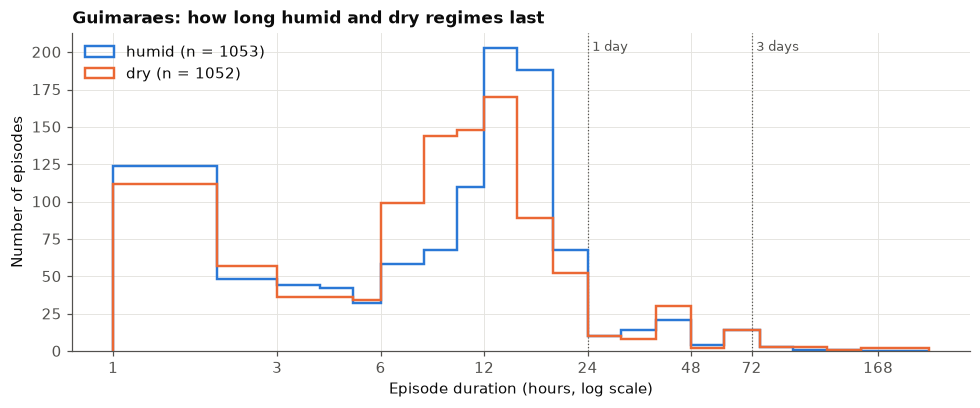

In [15]:
fig = plots.episode_durations(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_06_episode_durations")
plt.show()

Most humid episodes in Guimarães last about half a day, but a minority last one to several days, and those matter most for a textile store.

**What the output shows**
- **Typical episodes:** There are 1,053 humid episodes, with a mean of 12.5 h, a median of 12 h and P90 of 20 h. The histogram peaks at 12–24 h, which fits the daily cycle (humid night, dry day). There is also a large group of very short episodes (1–2 h), which are brief crossings of τ_H.
- **Long episodes:** 68 humid episodes last ≥ 24 h, 5 last ≥ 72 h, and the longest lasts 119 h (about 5 days). Episodes of at least a day contain 25% of all humid hours.
- **Seasons:** Humid episodes are longest in autumn (median 14 h, max 119 h) and winter (13 h, 83 h), and shortest in summer (10 h, max 38 h).
- **Dry vs. humid:** The episode counts and means are almost identical, but dry episodes have a longer tail (75 last ≥ 24 h, 11 last ≥ 72 h, max 235 h). Most humid episodes end within a day, while dry spells can last longer.

**What it means for the store**
- **Short episodes (hours)** follow the daily cycle and can be handled with routine control. Very short ones may not need any action.
- **Long episodes (≥ 1 day)** are the main risk. Textiles are exposed to continuous high humidity with no dry break, so dehumidification has to run for long periods without interruption. A quarter of all humid hours happen this way.
- **Autumn and winter** are when these sustained episodes occur, so that's where capacity planning should focus.
- **For forecasting:** Recognising early that a humid episode will last longer than the usual half day gives the store time to act before moisture builds up.

### Step 10: Profile humidity by month and hour

Original analysis (Ch. 3.2). Share of humid hours for each calendar month and local hour (true local clock, with summer time).

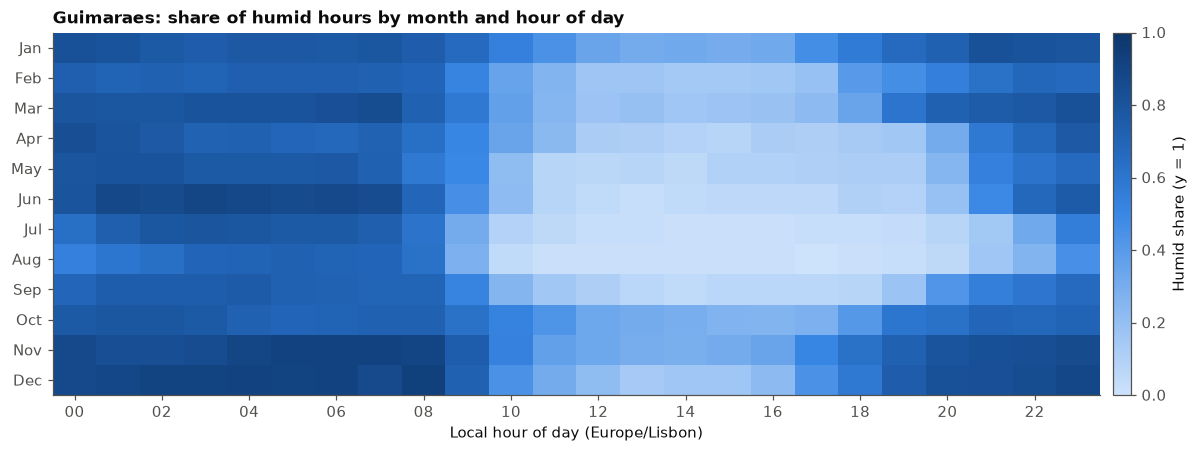

,most humid hour,max share,least humid hour,min share,amplitude (max - min)
season,,,,,
DJF,0,0.8081,15,0.2030,0.6052
MAM,0,0.8080,14,0.1014,0.7065
JJA,3,0.7935,13,0.0181,0.7754
SON,2,0.7875,14,0.2088,0.5788


In [16]:
fig = plots.hour_month_heatmap(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_07_hour_month_heatmap")
plt.show()
profile["daily_cycle"]

Guimarães has a clear daily dry window around midday and early afternoon, but how reliable it is depends strongly on the month.

**What the output shows**
- **Daily cycle:** In every season, the most humid hours fall at night (00–03 h, humid share 0.79–0.81) and the least humid in early afternoon (13–15 h).
- **Strength of the cycle:** The difference between the most and least humid hour is large in all seasons (0.58–0.78), so the hour of day matters a lot.
- **By season:**
  - **Summer (JJA):** This is the most reliable window. At 13 h almost no hours are humid (min share 0.02), and the heatmap shows a long, light band from late morning to early evening in July–August.
  - **Spring (MAM):** The window is reliable (min share 0.10 at 14 h) and wide, especially from April to June.
  - **Autumn (SON) and winter (DJF):** The window is weaker (min share about 0.21 at 14–15 h) and shorter. In the heatmap it narrows to the early afternoon in November–January, and even then some hours are humid.

**What it means for ventilation**
- **Spring and summer:** Ventilating from around midday to the afternoon is a dependable routine. Night ventilation should be avoided, since nights are mostly humid even in summer.
- **Autumn and winter:** There is still a better time of day (early afternoon), but it isn't guaranteed. Ventilation should be decided from actual or forecast conditions rather than a fixed schedule, with dehumidification as the backup.
- The hours are in local time (Europe/Lisbon), so the window can be used directly for scheduling.

### Step 11: Locate the long humid spells

Original analysis (Ch. 3.2). Each hour is labelled with the length of its episode. **Risk hours** are humid hours inside an episode of at least 24 h.

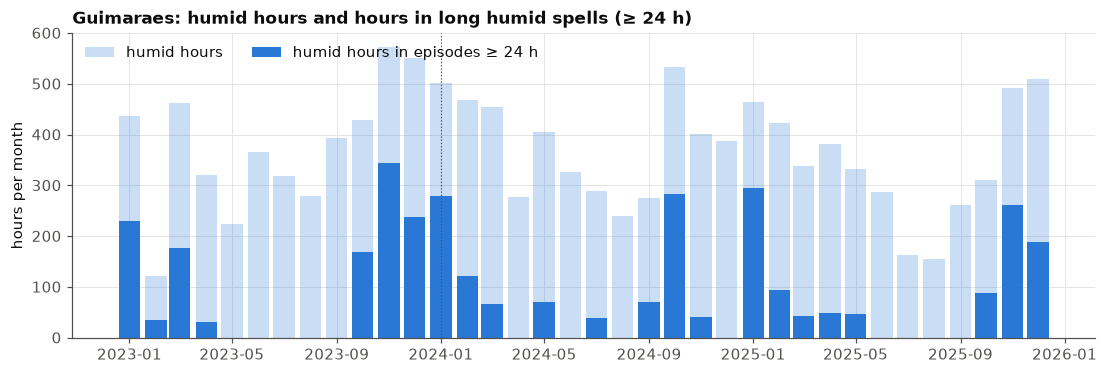

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
humid,467.0000,338.0000,418.0000,326.0000,321.0000,327.0000,257.0000,225.0000,311.0000,424.0000,489.0000,483.0000
risk,268.0000,84.0000,95.0000,27.0000,39.0000,0.0000,13.0000,0.0000,24.0000,180.0000,216.0000,142.0000


In [17]:
LONG_H = 24
run_id = (pdf["y"] != pdf["y"].shift()).cumsum()
run_len = pdf.groupby(run_id)["y"].transform("size")
risk = (pdf["y"] == 1) & (run_len >= LONG_H)

monthly = (pdf.assign(risk=risk, humid=pdf["y"] == 1)
              .groupby(pdf["timestamp"].dt.to_period("M"))[["humid", "risk"]].sum())
monthly["risk share of humid hours"] = monthly["risk"] / monthly["humid"]

fig, ax = plt.subplots(figsize=(12, 3.6))
x = monthly.index.to_timestamp()
ax.bar(x, monthly["humid"], width=25, color=HUMID, alpha=0.25, label="humid hours")
ax.bar(x, monthly["risk"], width=25, color=HUMID, label=f"humid hours in episodes ≥ {LONG_H} h")
ax.axvline(prepared["evaluation_start"], color=INK_2, linewidth=0.8, linestyle=":")
ax.set_ylabel("hours per month")
ax.set_title(f"{CITY['name']}: humid hours and hours in long humid spells (≥ {LONG_H} h)", loc="left")
ax.legend(loc="upper left", ncol=2)
plots.save(fig, cfg, f"{CITY_KEY}_08_long_humid_spells")
plt.show()

by_month = monthly.groupby(monthly.index.month)[["humid", "risk"]].mean().round(0)
by_month.index = plots.MONTHS
by_month.T

Risk hours are humid hours inside an episode of at least 24 h. They show when the store faces sustained humidity rather than short daily peaks.

**When to expect sustained humid spells**
- **October to January is the main risk period.** Average risk hours per month: Jan 268 (57% of its humid hours), Nov 216 (44%), Oct 180 (42%), Dec 142 (29%). In these months, a large part of the humidity comes in multi-day spells.
- **February and March** are moderate (84 and 95 risk hours).
- **April to September** has little sustained humidity, from 0 to 39 risk hours per month, with none in June or August. Humid hours still occur in these months, but almost entirely in short episodes.
- **Overall**, 25% of all humid hours are risk hours.
- **Year-to-year variation:** The chart shows big differences between years. Some winter months have a large share of risk hours (e.g. Nov–Dec 2023, Jan 2025), while others in the same season have few. A "normal" month can't be assumed.

**How to plan for it**
- **October to January:** Make sure there is enough dehumidification capacity to run continuously for several days. Avoid ventilating during spells, since there's no reliable dry break to use.
- **February to March:** Stay ready for occasional long spells.
- **April to September:** Short humid episodes can be handled with routine control and midday ventilation.
- **Forecasting:** Spotting early that a humid episode is turning into a long one (≥ 24 h) gives the store time to prepare, which is where a predictive model adds most value.

### Step 12: Save the profile tables

Used by `03_shared_comparison` and by the report.

In [18]:
profiling.save_profile(profile, CITY_KEY, output_dir(cfg, "profiles_dir"))
profile["key_numbers"].to_frame()

,value
tau_H,82.0000
humid_share_all,0.5002
humid_share_warmup,0.5108
humid_share_evaluation,0.4949
humid_share_DJF,0.5939
humid_share_MAM,0.4826
humid_share_JJA,0.3665
humid_share_SON,0.5602
rh_mean,76.9514
rh_std,18.2794


### Step 13: Interpret the stream for the warehouse

Descriptive evidence only (Ch. 9 item 7, Ch. 13.1).

For a textile storage facility in Guimarães, the stream shows that humidity is a recurring, seemingly predictable risk with a strong seasonal and daily structure.

- **Humidity is common.** Mean RH is 77%, and with τ_H = 82% about half of all hours are humid (50.0%). The store spends roughly as much time in the humid regime as in the dry one, so humidity control is a constant need, not an occasional one.
- **The risk is seasonal.** Winter (59% humid) and autumn (56%) are the most exposed, while summer is the driest (37%). Sustained humid spells concentrate from October to January, which is when continuous dehumidification capacity matters most.
- **There is a daily rhythm.** Nights are mostly humid and early afternoons mostly dry. This gives a usable ventilation window, reliable in spring and summer but weak in autumn and winter.
- **Most episodes are short, but some aren't.** Humid episodes last 12.5 h on average, but 68 lasted at least a day, 5 lasted at least three days, and the longest lasted 119 h. These long spells are the main threat to stored textiles.
- **Conditions change often.** The regime switches about 1.9 times per day in evaluation, so control has to respond within the day.
- **The regime is highly persistent hour to hour.** Simply predicting that the next hour matches the current one already reaches 92% accuracy and Macro-F1, far above the 50.5% from always predicting the majority class. Any forecasting model has to beat this high bar to add value. Its practical benefit would be anticipating switches and the start of long humid spells.

**In short:** A store in Guimarães should plan for year-round humidity management, with the most capacity in autumn and winter. In spring and summer, it can use midday ventilation to its advantage.

> **Main takeaways:** The descriptive analysis shows that Guimarães's humid regime is strongly structured: it follows a clear daily and seasonal cycle, switches about twice a day, and occasionally settles into multi-day humid spells. It is also highly persistent, since predicting that the next hour matches the current one already reaches 92% accuracy. This raises the central question for Stage 4: can learning models do better than this simple rule?
>
> Stage 4 tests this in the official prequential experiment. Five models are run on Representation A (current conditions) and Representation B (adding recent context through rolling windows, which Stage 3 suggested could help distinguish stable humid spells from daily swings). The aim is not only to rank scores but to see whether any gain over persistence holds up across errors, over time and relative to its computational cost.

## Stage 4: Run and evaluate the official prequential experiment

**What happens here:** Confirm that no future information reaches the features, then run the five mandatory models on both representations in strict PREDICT → EVALUATE → LEARN order and assess the results.

**What to investigate:** Do the models beat the persistence rule, does recent context help, which errors do they make, is performance stable over time, and is any gain worth its cost? Interpret the evidence together, rather than ranking the scores.

**Requirements covered:** Ch. 7 and 7.1 (leakage), Ch. 8 (Representations A and B), Ch. 10 (five models), Ch. 11 (predictive and computational evidence), Ch. 12 (experimental rules), Ch. 13.2 (evidence for the technical recommendation).

### Step 14: Test for leakage and build the two streams

The experiment uses two representations, five mandatory models, the same chronological history for every model, and PREDICT → EVALUATE → LEARN (Ch. 7, 8, 10–12).

**How the leakage test works.** A prediction for hour *t* must not use information from hour *t* or later. `check_no_leakage` tests this by tampering with a copy of the data, using hour 1000 as *t*:

1. **Corrupt the future.** Every weather value from hour 1000 onwards is replaced with the impossible value 9999, and the features are rebuilt. The features for hours 0–1000 must stay identical, because each one should only look backwards. If any of them changes, a feature is using current or future data, which is leakage.
2. **Corrupt the past (positive control).** Every weather value before hour 1000 is replaced with 9999. The features at hour 1000 must now change. If they don't, they ignore the past, and step 1 would have passed without proving anything.

If either check fails, the function raises an `AssertionError` and the cell stops, so "leakage test passed" only prints when both checks pass. The comparison covers hours 0–1000, and the remaining hours are built by the same rule.

**Which observations each feature uses.** RH at time *t* defines y_t, so it is never a predictor. No feature for time *t* uses a weather observation or label from time *t*: everything comes from *t*−1 or earlier (Ch. 7.1), because `shift(1)` is applied before any rolling calculation.

| Feature | Data used for the prediction at *t* |
|---|---|
| Representation A: temperature, RH, precipitation, wind | *t*−1 |
| RH delta (B) | *t*−1 minus *t*−2 |
| 6 h rolling mean and std of RH (B) | *t*−1 to *t*−6 |
| 24 h rolling mean and std of RH (B) | *t*−1 to *t*−24 |
| Humid hours in the last 24 h (B) | labels from *t*−1 to *t*−24 |

The label y_t only reaches the model in the LEARN step, after the prediction for *t* has been scored. The hour-of-day experiment (E3, Step 23) uses the clock time of *t*, which is known in advance and is not a weather observation. It is not part of the official run.

In [4]:
# raises AssertionError if leakage is found
check_no_leakage(prepared["raw"][CITY_KEY], TAU_H, cfg)

# only reached if the check above passes
print("leakage test passed")                              


streams = make_streams(prepared, cfg)[CITY_KEY]
pd.DataFrame({rep: {"warm-up events": len(s["warm"]), "evaluation events": len(s["eval"]),
                    "features": len(s["eval"][0]["x"]), "names": ", ".join(s["eval"][0]["x"])}
              for rep, s in streams.items()}).T

leakage test passed


,warm-up events,evaluation events,features,names
A,8736,17544,4,"temperature_2m_lag1, relative_humidity_2m_lag1..."
B,8736,17544,10,"temperature_2m_lag1, relative_humidity_2m_lag1..."


* **Representation A** (previous state): temperature, RH, precipitation and wind at t−1.
* **Representation B** (A + temporal context): RH delta (t−1 minus t−2), 6 h and 24 h rolling mean and std of RH, humid hours in the previous 24 h. All windows end at t−1.
* The first 24 warm-up hours have no complete 24 h window and are dropped for both representations (8 736 warm-up events); the evaluation stream is complete (17 544 events = every hour of 2024–2025).
* Scalers are fitted on the pooled warm-up of both cities and frozen; models learn on the warm-up without being scored.

### Step 15: Run the official experiment and save the results

This is the main experiment of the notebook. It produces the official Guimarães results that are reported and compared in `03_shared_comparison`.

**What is run.** The five mandatory models (Gaussian Naive Bayes, Online Logistic Regression, Hoeffding Tree, Online Bagging, Adaptive Random Forest) each run on Representations A and B, which gives 10 runs. Every run starts from a fresh model and uses the same events in the same order, so differences between runs come only from the model or the representation (Ch. 12.7–12.8). Settings and the random seed (42) come from `config.yaml`.

**How each run works** (`evaluate.run_prequential`):

1. **Warm-up (2023, 8,736 events):** the model learns from each event in order. Nothing is scored.
2. **Evaluation (2024–2025, 17,544 events):** for each hour, in strict chronological order:
   * **PREDICT:** the model predicts humid or dry from the features, which only contain past information.
   * **EVALUATE:** the prediction is compared with the true label and the scores are updated.
   * **LEARN:** the model then learns from that event, so the label can only help with later hours.

There is no random train/test split: every evaluation hour is predicted once, by a model that has only seen earlier hours (Ch. 3, 12.1, 12.6).

**What is measured.** Positive class = humid.

* Accuracy, Macro-F1, Precision, Recall and confusion counts over the whole evaluation period (Ch. 11.1).
* Recent Accuracy and Macro-F1 over the last 500 events, recorded every 24 events, to follow performance over time (Step 19).
* Prediction and update time per event (Ch. 11.2, Step 20).

**The reference.** The table also includes the persistence rule, which predicts that the regime stays the same as in the previous hour (ŷ_t = y_{t−1}). It needs no training and uses the same evaluation hours, so a model only adds value if it beats this rule. The last column shows each model's Macro-F1 difference from it.

**What is saved.** `save_results` writes `results/metrics_guimaraes.csv` and `results/history_guimaraes.csv`, which notebook 03 reads. Only this official run is saved; the experiments in Stage 5 are not.

In [20]:
metrics, history = evaluate_models(streams, make_models, cfg, CITY_KEY)   # 2 representations x 5 models
save_results(metrics, history, CITY_KEY, cfg)                             # official run only

ref = profile["persistence_reference"]          # persistence rule y_hat_t = y_{t-1}, same evaluation hours
COLS = ["accuracy", "macro_f1", "precision", "recall"]
table = metrics.set_index(["representation", "model"])[COLS]
table.loc[("—", "Persistence rule (y_t-1)"), :] = ref[COLS].values
table["Δ macro_f1 vs persistence"] = table["macro_f1"] - ref["macro_f1"]
table.round(4)

accuracy  macro_f1  precision  \
representation model                                                       
A              Gaussian Naive Bayes          0.9126    0.9125     0.9319   
               Online Logistic Regression    0.8908    0.8907     0.8585   
               Hoeffding Tree                0.9195    0.9195     0.9178   
               Online Bagging                0.9204    0.9204     0.9208   
               Adaptive Random Forest        0.9191    0.9191     0.9155   
B              Gaussian Naive Bayes          0.8800    0.8798     0.8992   
               Online Logistic Regression    0.9066    0.9066     0.8841   
               Hoeffding Tree                0.9342    0.9342     0.9233   
               Online Bagging                0.9415    0.9415     0.9372   
               Adaptive Random Forest        0.9364    0.9364     0.9334   
—              Persistence rule (y_t-1)      0.9204    0.9204     0.9196   

                                           recall  Δ macro_f1 vs persistence  
representation model                                                          
A              Gaussian Naive Bayes        0.8884                    -0.0079  
               Online Logistic Regression  0.9333                    -0.0297  
               Hoeffding Tree              0.9196                    -0.0010  
               Online Bagging              0.9182                    -0.0000  
               Adaptive Random Forest      0.9216                    -0.0014  
B              Gaussian Naive Bayes        0.8530                    -0.0406  
               Online Logistic Regression  0.9338                    -0.0138  
               Hoeffding Tree              0.9456                     0.0138  
               Online Bagging              0.9452                     0.0211  
               Adaptive Random Forest      0.9385                     0.0160  
—              Persistence rule (y_t-1)    0.9196                     0.0000

Here, we are trying to answer one question: **do the incremental models add value over the persistence rule here?**

Persistence sets a high bar (Macro-F1 0.9204), and only some of the incremental models clear it, depending on the representation.

- **Representation A (current conditions):** No model beats persistence. Online Bagging only matches it (0.9204), and Hoeffding Tree (0.9195) and ARF (0.9191) fall just below. Gaussian NB (0.9125) and Logistic Regression (0.8907) are clearly worse. With current conditions alone, the models learn little beyond "the next hour looks like this one".
- **Representation B (with recent context):** The three tree-based models beat persistence: Online Bagging 0.9415 (+0.021), ARF 0.9364 (+0.016) and Hoeffding Tree 0.9342 (+0.014). Logistic Regression (0.9066) and Gaussian NB (0.8798) stay below, and NB does worse with B than with A.
- **Errors:** Online Bagging B is balanced, with precision 0.937 and recall 0.945, and improves both compared with persistence (0.920 each). Gaussian NB B misses the most humid hours (recall 0.853).
- **Interpretation:** Recent context is what adds value, but only flexible tree-based models can make use of it. The gains are real but modest (about 1.5–2 points of Macro-F1).

> **Provisional answer:** Yes, but only for the tree-based models on Representation B. Whether this gain is worth it depends on how stable it is over time and what it costs to compute, which the next steps examine.

### Step 16: Compare the models with the persistence rule

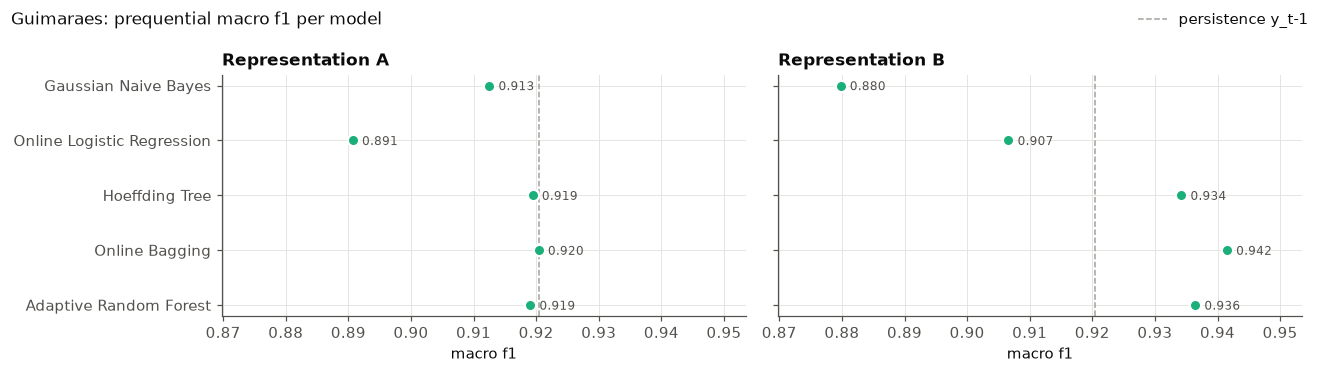

In [21]:
def dot_plot(metrics, ref, metric="macro_f1"):
    """One panel per representation; dashed line = persistence rule of this city."""
    models = list(dict.fromkeys(metrics["model"]))[::-1]
    vals = pd.concat([metrics[metric], pd.Series([ref[metric]])])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, sharex=True)
    for ax, rep in zip(axes, ["A", "B"]):
        sub = metrics[metrics["representation"] == rep].set_index("model").loc[models, metric]
        ax.axvline(ref[metric], color=GREY, linestyle="--", linewidth=1, label="persistence y_t-1")
        ax.scatter(sub, range(len(models)), s=55, color=AQUA, edgecolor="white", linewidth=1.5, zorder=3)
        for i, v in enumerate(sub):
            ax.annotate(f"{v:.3f}", (v, i), xytext=(6, -3), textcoords="offset points", fontsize=8, color=INK_2)
        ax.set_yticks(range(len(models)), models)
        ax.set_xlim(vals.min() - 0.01, vals.max() + 0.012)
        ax.set_xlabel(metric.replace("_", " "))
        ax.set_title(f"Representation {rep}", loc="left")
    fig.suptitle(f"{CITY['name']}: prequential {metric.replace('_', ' ')} per model", x=0.01, ha="left")
    fig.tight_layout()
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right")
    return fig

fig = dot_plot(metrics, ref, "macro_f1")
plots.save(fig, cfg, f"{CITY_KEY}_09_models_vs_persistence")
plt.show()

### Step 17: Compare Representations A and B

The common comparison question (Ch. 8). Same models, same events; only the representation changes (Ch. 12.10).

In [22]:
wide = metrics.pivot_table(index="model", columns="representation", values=["macro_f1", "recall"], sort=False)
gain = pd.DataFrame({
    "macro_f1 A": wide[("macro_f1", "A")], "macro_f1 B": wide[("macro_f1", "B")],
    "Δ macro_f1 (B − A)": wide[("macro_f1", "B")] - wide[("macro_f1", "A")],
    "Δ recall humid (B − A)": wide[("recall", "B")] - wide[("recall", "A")],
})
gain.round(4)

,macro_f1 A,macro_f1 B,Δ macro_f1 (B − A),Δ recall humid (B − A)
model,,,,
Gaussian Naive Bayes,0.9125,0.8798,-0.0327,-0.0354
Online Logistic Regression,0.8907,0.9066,0.0159,0.0005
Hoeffding Tree,0.9195,0.9342,0.0148,0.0260
Online Bagging,0.9204,0.9415,0.0211,0.0269
Adaptive Random Forest,0.9191,0.9364,0.0174,0.0169


The question to answer is: **does context help for Guimarães, for which learners, and why?**

Recent context helps four of the five learners in Guimarães, but it helps the tree-based models most and harms Gaussian Naive Bayes.

- **Tree-based models gain the most.** From A to B, Online Bagging improves by +0.021 Macro-F1, ARF by +0.017 and Hoeffding Tree by +0.015, and all three move from around persistence to clearly above it. They also catch more humid hours (recall +0.017 to +0.027), which is the costly error for the store.
- **Logistic Regression improves in Macro-F1 (+0.016) but not in humid recall (+0.001).** Its gain mostly comes from fewer false alarms rather than fewer missed humid hours, and it stays below persistence in both representations.
- **Gaussian NB gets worse** (−0.033 Macro-F1, −0.035 recall). It is the only model harmed by context.

**Why (likely explanation):**
- The context features (rolling means and std) are closely related to each other and to current RH. **Naive Bayes assumes features are independent**, so it effectively counts the same information several times, which distorts its probabilities.
- **Logistic Regression** is linear, so it can only partly use combinations such as "high 24 h mean *and* low volatility".
- **Trees** split on thresholds and combinations of features, which matches the patterns seen in Stage 3: stable humid spells versus regular daily swings. This lets them use context to anticipate regime switches.

> **Takeaway:** Context is useful for Guimarães, but only when combined with a learner that can model interactions between features.

### Step 18: Inspect the confusion matrices

Confusion counts for all runs, then the best model of each representation as a figure (Ch. 11.1). Positive class = humid.

tn    fp    fn    tp  \
representation model                                                
A              Gaussian Naive Bayes        8297   564   969  7714   
               Online Logistic Regression  7525  1336   579  8104   
               Hoeffding Tree              8146   715   698  7985   
               Online Bagging              8175   686   710  7973   
               Adaptive Random Forest      8122   739   681  8002   
B              Gaussian Naive Bayes        8031   830  1276  7407   
               Online Logistic Regression  7798  1063   575  8108   
               Hoeffding Tree              8179   682   472  8211   
               Online Bagging              8311   550   476  8207   
               Adaptive Random Forest      8280   581   534  8149   

                                           missed humid hours (fn) %  \
representation model                                                   
A              Gaussian Naive Bayes                          11.2000   
               Online Logistic Regression                     6.7000   
               Hoeffding Tree                                 8.0000   
               Online Bagging                                 8.2000   
               Adaptive Random Forest                         7.8000   
B              Gaussian Naive Bayes                          14.7000   
               Online Logistic Regression                     6.6000   
               Hoeffding Tree                                 5.4000   
               Online Bagging                                 5.5000   
               Adaptive Random Forest                         6.1000   

                                           false alarms (fp) %  
representation model                                            
A              Gaussian Naive Bayes                     6.4000  
               Online Logistic Regression              15.1000  
               Hoeffding Tree                           8.1000  
               Online Bagging                           7.7000  
               Adaptive Random Forest                   8.3000  
B              Gaussian Naive Bayes                     9.4000  
               Online Logistic Regression              12.0000  
               Hoeffding Tree                           7.7000  
               Online Bagging                           6.2000  
               Adaptive Random Forest                   6.6000

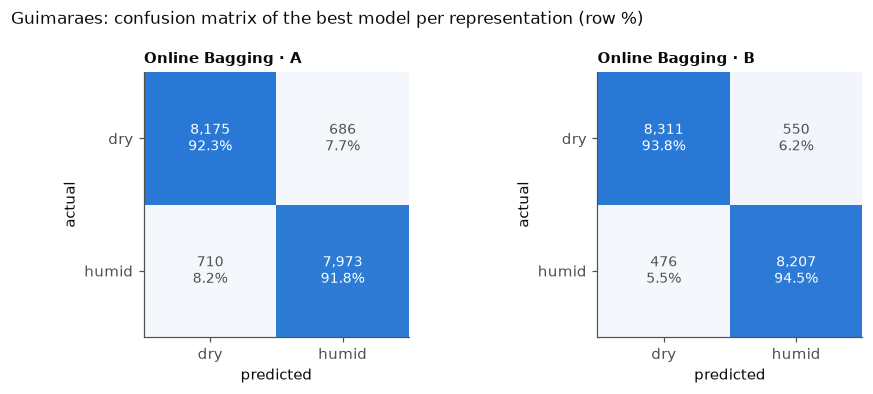

In [23]:
cm = metrics.set_index(["representation", "model"])[["tn", "fp", "fn", "tp"]]
cm["missed humid hours (fn) %"] = 100 * cm["fn"] / (cm["fn"] + cm["tp"])
cm["false alarms (fp) %"] = 100 * cm["fp"] / (cm["fp"] + cm["tn"])
display(cm.round(1))

best = metrics.loc[metrics.groupby("representation")["macro_f1"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
cmap = LinearSegmentedColormap.from_list("cm", ["#f4f8fd", BLUE])
for ax, (_, r) in zip(axes, best.iterrows()):
    m = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    ax.imshow(m, cmap=cmap)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(m[i, j]):,}\n{m[i, j] / m[i].sum():.1%}", ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else INK_2, fontsize=9)
    ax.set_xticks([0, 1], ["dry", "humid"]); ax.set_yticks([0, 1], ["dry", "humid"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.grid(False)
    ax.set_title(f"{r['model']} · {r['representation']}", loc="left", fontsize=10)
fig.suptitle(f"{CITY['name']}: confusion matrix of the best model per representation (row %)", x=0.01, ha="left")
fig.tight_layout()
plots.save(fig, cfg, f"{CITY_KEY}_10_confusion_best")
plt.show()

Here we have to question **which error is worse for the store, a missed humid hour or a false alarm, and which model handles that best?**

For a textile store, a missed humid hour is the more costly error: the store doesn't react while moisture builds up. A false alarm only means unnecessary dehumidification or a skipped ventilation.

- **Online Bagging B handles it best overall.** It misses 5.5% of humid hours (476 of 8,683) and raises 6.2% false alarms (550 of 8,861), the best balance of both errors. Compared with Online Bagging A (8.2% missed, 7.7% false alarms), context reduces both errors, especially the missed humid hours.
- **Hoeffding Tree B misses almost exactly as few humid hours (5.4%, 472)** but raises more false alarms (7.7%). ARF B is close behind (6.1% / 6.6%).
- **Logistic Regression** misses relatively few humid hours (6.6–6.7%) but raises many false alarms (15.1% in A, 12.0% in B). It is "safe" for textiles, but costly to run.
- **Gaussian NB B** is the weakest choice for the store: it misses the most humid hours (14.7%).

> **Takeaway:** Since missed humid hours matter most, the tree-based models on Representation B are the strongest candidates. Online Bagging B gives the best trade-off, keeping missed hours low without adding false alarms.

### Step 19: Track performance over time

Sliding-window Macro-F1 over the last 500 events (`protocol.evaluation_window`).

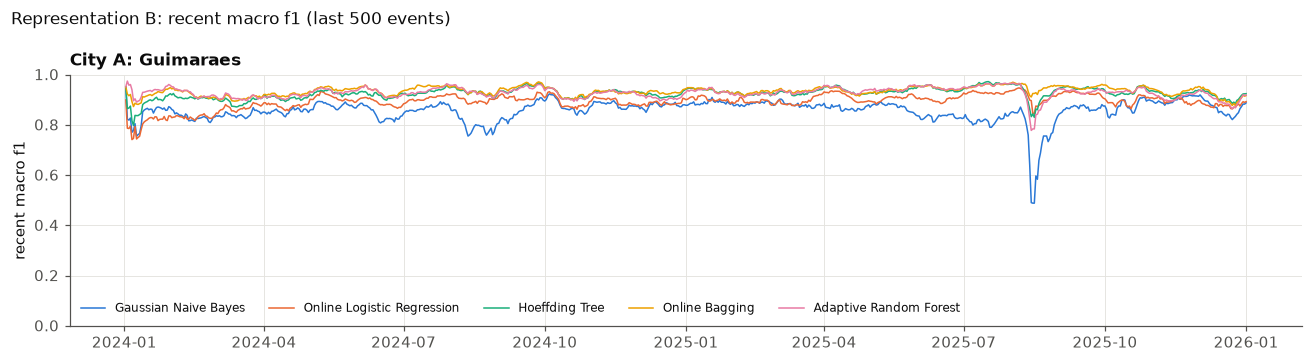

,min,max,worst window ends,best window ends
model,,,,
Adaptive Random Forest,0.7779,0.9669,2025-08-13,2025-08-01
Gaussian Naive Bayes,0.4882,0.9232,2025-08-14,2024-10-03
Hoeffding Tree,0.8298,0.9721,2025-08-15,2025-07-16
Online Bagging,0.8765,0.9711,2025-12-24,2024-09-26
Online Logistic Regression,0.8169,0.9471,2024-01-22,2025-08-05


,mean recent macro F1 (all models)
season,
DJF,0.9018
MAM,0.9080
JJA,0.9068
SON,0.9155


In [24]:
season_of = pdf.set_index("timestamp")["season"]
lookup_season = lambda ts: season_of.loc[ts].values

fig = plots.recent_performance(history, cfg, representation="B")
plots.save(fig, cfg, f"{CITY_KEY}_11_recent_macro_f1_B")
plt.show()

W = cfg["protocol"]["evaluation_window"]
h = history[(history["representation"] == "B") & (history["n"] >= W)]     # skip the first, not yet full window
summary = h.groupby("model")["recent_macro_f1"].agg(["min", "idxmin", "max", "idxmax"])
summary["worst window ends"] = h.loc[summary["idxmin"], "timestamp"].dt.strftime("%Y-%m-%d").values
summary["best window ends"] = h.loc[summary["idxmax"], "timestamp"].dt.strftime("%Y-%m-%d").values
display(summary.drop(columns=["idxmin", "idxmax"]))
by_season = h.assign(season=lookup_season(h["timestamp"])).groupby("season", observed=True)["recent_macro_f1"].mean()
by_season.to_frame("mean recent macro F1 (all models)")

Performance in Representation B is mostly stable, but it drops sharply during one period: mid-August 2025.

**When performance drops**
- **Mid-August 2025 is the main drop.** ARF, Gaussian NB and Hoeffding Tree all reach their lowest recent Macro-F1 between 13 and 15 Aug 2025 (ARF 0.778, NB 0.488, HT 0.830). The plot shows a short, deep dip, followed by a recovery within a few weeks.
- **Other lows are milder and isolated.** Online Bagging's worst window ends on 24 Dec 2025 (0.877) and Logistic Regression's on 22 Jan 2024 (0.817), right at the start of evaluation. Gaussian NB also has a smaller dip around Aug–Sep 2024.
- **Seasonal averages are flat** (0.90–0.92 across all models), so there is no season that is systematically harder. The drops are short episodes.
- **Online Bagging is the most stable model.** Its lowest value (0.877) is clearly above every other model's, and its best and worst windows are close together.

**What is happening in the weather**
- The August 2025 drop falls in the **driest part of the evaluation period**. Stage 3 showed July–August 2025 with very few humid hours, the year's highest temperatures (39.8 °C on 5 Aug 2025 at RH 17%), and some of the driest days.
- When humid hours become very rare within the 500-hour window, the **few remaining humid hours dominate the humid-class F1**. Even a handful of errors lowers Macro-F1 sharply. So the drop is partly an effect of the metric under extreme class imbalance, and partly the models facing conditions outside their usual range.
- The models recover once humid hours return in late August and September, which shows they adapt after the unusual period.

> **Takeaway:** The models are reliable most of the time, but the most unusual weather (an extreme dry and hot spell) is where they are weakest. Online Bagging handles it best.

### Step 20: Measure prediction and update cost

Prediction and update time per event (Ch. 11.2), in milliseconds on an Apple Silicon machine. Absolute values depend on the hardware, so compare ratios.

macro_f1  pred_ms_per_event  \
representation model                                                     
A              Gaussian Naive Bayes          0.9125             0.0283   
               Online Logistic Regression    0.8907             0.0004   
               Hoeffding Tree                0.9195             0.0023   
               Online Bagging                0.9204             0.0123   
               Adaptive Random Forest        0.9191             0.0191   
B              Gaussian Naive Bayes          0.8798             0.0260   
               Online Logistic Regression    0.9066             0.0005   
               Hoeffding Tree                0.9342             0.0022   
               Online Bagging                0.9415             0.0130   
               Adaptive Random Forest        0.9364             0.0182   

                                           update_ms_per_event  \
representation model                                             
A              Gaussian Naive Bayes                     0.0012   
               Online Logistic Regression               0.0010   
               Hoeffding Tree                           0.0044   
               Online Bagging                           0.0243   
               Adaptive Random Forest                   0.1519   
B              Gaussian Naive Bayes                     0.0017   
               Online Logistic Regression               0.0012   
               Hoeffding Tree                           0.0075   
               Online Bagging                           0.0437   
               Adaptive Random Forest                   0.1467   

                                           total ms / event  
representation model                                         
A              Gaussian Naive Bayes                  0.0295  
               Online Logistic Regression            0.0014  
               Hoeffding Tree                        0.0068  
               Online Bagging                        0.0366  
               Adaptive Random Forest                0.1709  
B              Gaussian Naive Bayes                  0.0277  
               Online Logistic Regression            0.0018  
               Hoeffding Tree                        0.0098  
               Online Bagging                        0.0566  
               Adaptive Random Forest                0.1649

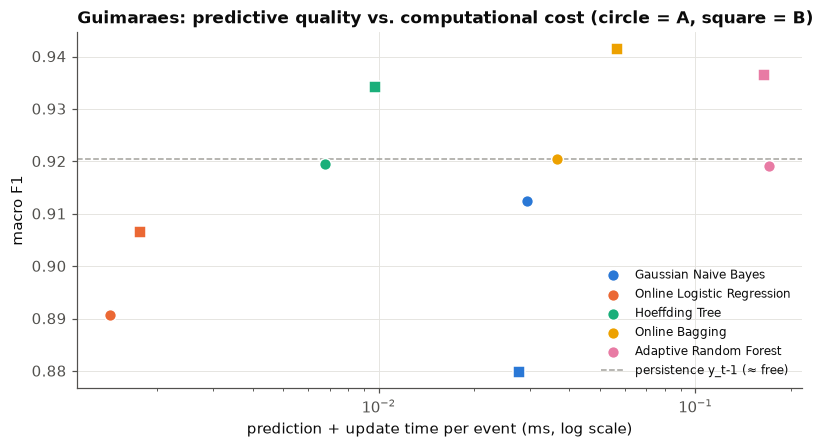

In [25]:
cost = metrics.set_index(["representation", "model"])[["macro_f1", "pred_ms_per_event", "update_ms_per_event"]]
cost["total ms / event"] = cost["pred_ms_per_event"] + cost["update_ms_per_event"]
display(cost.round(4))

markers = {"A": "o", "B": "s"}
models = list(dict.fromkeys(metrics["model"]))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for m, color in zip(models, MODEL_COLORS):
    for rep in ("A", "B"):
        r = metrics[(metrics["model"] == m) & (metrics["representation"] == rep)].iloc[0]
        ax.scatter(r["pred_ms_per_event"] + r["update_ms_per_event"], r["macro_f1"], s=60, color=color,
                   marker=markers[rep], edgecolor="white", linewidth=1, zorder=3,
                   label=m if rep == "A" else None)
ax.axhline(ref["macro_f1"], color=GREY, linestyle="--", linewidth=1, label="persistence y_t-1 (≈ free)")
ax.set_xscale("log")
ax.set_xlabel("prediction + update time per event (ms, log scale)")
ax.set_ylabel("macro F1")
ax.set_title(f"{CITY['name']}: predictive quality vs. computational cost (circle = A, square = B)", loc="left")
ax.legend(fontsize=8, loc="lower right")
plots.save(fig, cfg, f"{CITY_KEY}_12_quality_vs_cost")
plt.show()

Is the gain of the ensembles worth their cost? All models are very cheap for an hourly stream, so cost doesn't limit the choice here. Accuracy, error type and stability decide.

- **Absolute cost is tiny.** The stream produces one event per hour, and every model needs well under 1 ms per event (at most about 0.17 ms for ARF). Even the slowest model uses a negligible fraction of the time available between events.
- **Relative cost differs a lot.** In Representation B, ARF (≈0.165 ms) costs about 3× Online Bagging (≈0.057 ms), ≈17× Hoeffding Tree (≈0.010 ms) and ≈90× Logistic Regression (≈0.002 ms).
- **Context adds some update cost.** From A to B, update time grows for Hoeffding Tree (0.0044 → 0.0075 ms) and Online Bagging (0.024 → 0.044 ms) and stays about the same for ARF. The extra cost is small compared with the gain in Macro-F1.
- **Cost vs. quality:** ARF B is the most expensive model but scores below Online Bagging B (0.936 vs. 0.942), so its extra cost buys nothing. Hoeffding Tree B gets most of the gain (0.934) at a fraction of the cost.

>**Recommendation for continuous monitoring (Ch. 13.2)**
>- **Online Bagging on Representation B** is the best choice. It has the highest Macro-F1 (0.942), the best balance of missed humid hours and false alarms, and the most stable performance over time, at a cost that is negligible for hourly data.
>- **Hoeffding Tree on Representation B** is a good lightweight alternative if resources are very limited, for example on a small on-site device, with only a small loss in quality.
>- The **gain over persistence is modest** (+0.021 Macro-F1), but it is consistent and comes mostly from fewer missed humid hours, which is the error that matters most for textiles.

## Stage 5: Diagnose errors and run additional experiments

**What happens here:** Look inside the best official model's errors, test how early it detects long humid spells, then test whether other context features would help, changing one factor at a time. This is additional analysis and never replaces the official results.

**What to investigate:** Where do the errors concentrate, what limits one-hour-ahead prediction, are long humid spells detected at their start, and would any experiment justify a shared protocol change?

**Requirements covered:** Ch. 3.2 (original analysis), Ch. 8 (additional justified features must stay leakage-free), Ch. 12.7 (fresh model instances), Ch. 12.10 (one scientific factor at a time).

### Step 21: Diagnose the prediction errors

Steps 21–23 are additional analysis, not part of the official comparison. Step 23 uses a copy of the configuration and fresh models. Nothing is saved with `save_results`, so the official results and notebook 03 are unchanged. One factor changes at a time (Ch. 12.10).

`run_prequential` reports aggregate metrics only. To see which hours are misclassified, the best official model (Online Bagging, Representation B) is replayed with a fresh instance, the same events and the same PREDICT → EVALUATE → LEARN order, storing each prediction. An assertion checks that the replay reproduces the official accuracy exactly.

In [26]:
def replay_predictions(model, stream):
    """Diagnostic copy of the prequential order: learn on warm-up, then PREDICT -> (store) -> LEARN."""
    for e in stream["warm"]:
        model.learn_one(e["x"], e["y"])
    rows = []
    for e in stream["eval"]:
        y_pred = model.predict_one(e["x"])          # 1) predict with past-only state
        rows.append((e["timestamp"], e["y"], y_pred))  # 2) evaluated below, before nothing else uses y
        model.learn_one(e["x"], e["y"])             # 3) learn
    return pd.DataFrame(rows, columns=["timestamp", "y", "pred"])

BEST = "Online Bagging"
diag = replay_predictions(make_models(cfg)[BEST], streams["B"])
official = metrics[(metrics["model"] == BEST) & (metrics["representation"] == "B")]["accuracy"].iloc[0]
assert abs((diag["pred"] == diag["y"]).mean() - official) < 1e-12, "replay differs from the official run"

lookup = pdf.set_index("timestamp")
diag["rh"] = lookup.loc[diag["timestamp"], "relative_humidity_2m"].values
diag["y_prev"] = lookup["y"].shift(1).loc[diag["timestamp"]].values
diag["switch"] = diag["y"] != diag["y_prev"]                   # the regime changes at this hour
diag["model_error"] = diag["pred"] != diag["y"]
diag["persistence_error"] = diag["y_prev"] != diag["y"]        # persistence is wrong exactly at switches
diag["distance to tau_H (pp)"] = (diag["rh"] - TAU_H).abs()

by_switch = diag.groupby(diag["switch"].map({False: "regime continues", True: "regime switches"})).agg(
    hours=("y", "size"), model_errors=("model_error", "sum"), persistence_errors=("persistence_error", "sum"))
by_switch["model error rate"] = by_switch["model_errors"] / by_switch["hours"]
by_switch["share of all model errors"] = by_switch["model_errors"] / by_switch["model_errors"].sum()
display(by_switch.round(3))

bands = pd.cut(diag["distance to tau_H (pp)"], [-0.1, 1, 3, 5, 10, 100], labels=["≤ 1", "1–3", "3–5", "5–10", "> 10"])
by_band = diag.groupby(bands, observed=True).agg(
    hours=("y", "size"), model_error_rate=("model_error", "mean"), persistence_error_rate=("persistence_error", "mean"))
by_band["share of hours"] = by_band["hours"] / by_band["hours"].sum()
by_band["share of model errors"] = diag.groupby(bands, observed=True)["model_error"].sum() / diag["model_error"].sum()
by_band.round(3)

,hours,model_errors,persistence_errors,model error rate,share of all model errors
switch,,,,,
regime continues,16148,223,0,0.0140,0.2170
regime switches,1396,803,1396,0.5750,0.7830


,hours,model_error_rate,persistence_error_rate,share of hours,share of model errors
distance to tau_H (pp),,,,,
≤ 1,870,0.3970,0.4510,0.0500,0.3360
1–3,1270,0.2610,0.3240,0.0720,0.3230
3–5,1197,0.1300,0.2230,0.0680,0.1520
5–10,3731,0.0400,0.0730,0.2130,0.1440
> 10,10476,0.0040,0.0050,0.5970,0.0450


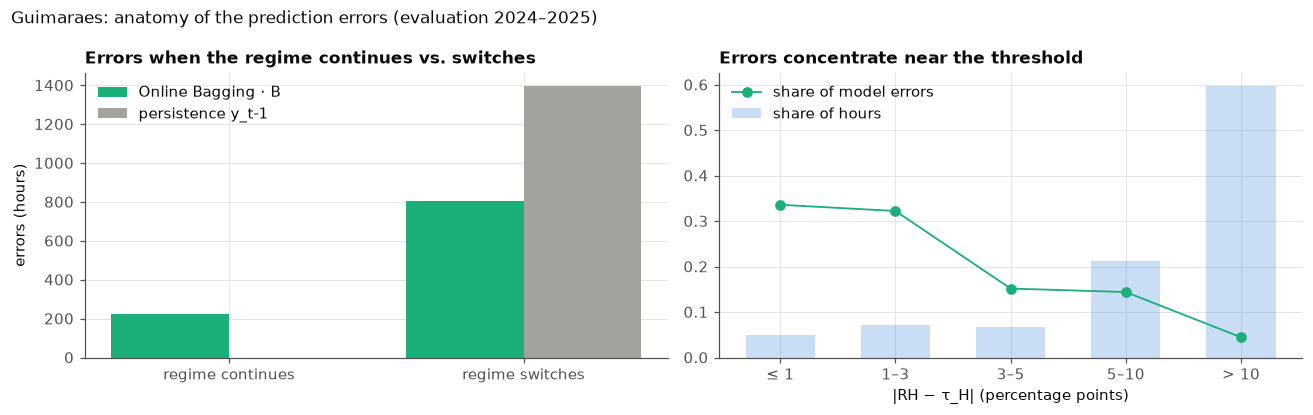

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
x = np.arange(len(by_switch))
ax.bar(x - 0.2, by_switch["model_errors"], 0.4, color=AQUA, label=f"{BEST} · B")
ax.bar(x + 0.2, by_switch["persistence_errors"], 0.4, color=GREY, label="persistence y_t-1")
ax.set_xticks(x, by_switch.index); ax.set_ylabel("errors (hours)")
ax.set_title("Errors when the regime continues vs. switches", loc="left"); ax.legend()
ax = axes[1]
x = np.arange(len(by_band))
ax.bar(x, by_band["share of hours"], 0.6, color=HUMID, alpha=0.25, label="share of hours")
ax.plot(x, by_band["share of model errors"], "o-", color=AQUA, label="share of model errors")
ax.set_xticks(x, by_band.index); ax.set_xlabel("|RH − τ_H| (percentage points)")
ax.set_title("Errors concentrate near the threshold", loc="left"); ax.legend()
fig.suptitle(f"{CITY['name']}: anatomy of the prediction errors (evaluation 2024–2025)", x=0.01, ha="left")
fig.tight_layout()
plots.save(fig, cfg, f"{CITY_KEY}_exp_error_anatomy")
plt.show()

Predicting T4 one hour ahead in Guimarães is easy most of the time. The difficulty is concentrated in a small number of hours: when the regime switches and when RH is close to τ_H.

- **Switches are the core problem.** The regime switches in only 1,396 of 17,544 evaluation hours (8.0%), and persistence is wrong in exactly those hours.
- **The model adds value at switches.** Online Bagging B gets 593 of the 1,396 switches right (42%). In exchange, it makes 223 errors when the regime continues, hours that persistence always gets right. Overall that's 370 fewer errors than persistence (1,026 vs. 1,396).
- **Switches still dominate its errors.** 78% of the model's errors happen at switches, where its error rate is 57.5%, compared with 1.4% when the regime continues.
- **Errors cluster near the threshold.** 66% of the errors happen within ±3 points of τ_H, where only 12% of hours lie. More than 10 points away (60% of hours), the error rate is just 0.4%. The model also beats persistence in every distance band, most clearly between 3 and 10 points.

**What it means**
- Far from τ_H, the next hour is almost always predictable, by the model or by persistence.
- Near τ_H, small changes in RH flip the label, so some errors there are unavoidable. Part of this comes from the hard 82% cut-off rather than from the model itself.
- **For the store:** Predictions are very reliable when RH is clearly above or below 82%. Predictions close to the threshold are the uncertain ones and should be treated with more caution, for example by acting early when RH is approaching τ_H from below.

### Step 22: Test early detection of long humid spells

Additional analysis, specific to this notebook. Steps 9 and 11 identified long humid spells as the main risk for the store. This step tests whether Online Bagging B detects them at the moment they matter most: **the first hour of the spell**.

Using the predictions stored in Step 21, each humid episode that starts during the evaluation period is grouped by its full length. An episode counts as **caught** if the model predicts humid for its first hour, when the previous hour was still dry. Persistence can never catch this hour, because it always repeats the previous regime.

The model does not know how long an episode will last, so the groups only show whether long spells are easier or harder to detect at the start. The last line before the table shows how often a humid prediction after a dry hour is correct, because catching more onsets is only useful if most of those alerts are right.

In [30]:
# Every evaluation hour that starts a humid episode, with the full length of that episode
episode_len = pdf.assign(run_len=run_len).set_index("timestamp")["run_len"]
onsets = diag[diag["switch"] & (diag["y"] == 1)].copy()
onsets["episode length"] = pd.cut(episode_len.loc[onsets["timestamp"]].to_numpy(),
                                  [0, 5, LONG_H - 1, np.inf],
                                  labels=["1–5 h", f"6–{LONG_H - 1} h", f"≥ {LONG_H} h"])
onsets["caught"] = onsets["pred"] == 1

onset_table = onsets.groupby("episode length", observed=True)["caught"].agg(episodes="size", caught_by_model="sum")
onset_table.loc["all humid episodes"] = onset_table.sum()
onset_table["model share"] = onset_table["caught_by_model"] / onset_table["episodes"]
onset_table["caught_by_persistence"] = 0                # persistence always predicts the previous (dry) regime

# Context: how often is a humid prediction right when the previous hour was dry?
after_dry = diag[diag["y_prev"] == 0]
alarms = after_dry[after_dry["pred"] == 1]
print(f"previous hour dry: {len(after_dry)} hours | model predicts humid: {len(alarms)} hours | "
      f"correct: {(alarms['y'] == 1).sum()} ({(alarms['y'] == 1).mean():.1%})")
onset_table.round(3)


previous hour dry: 8861 hours | model predicts humid: 445 hours | correct: 309 (69.4%)


,episodes,caught_by_model,model share,caught_by_persistence
episode length,,,,
1–5 h,192,73,0.3800,0
6–23 h,463,227,0.4900,0
≥ 24 h,43,9,0.2090,0
all humid episodes,698,309,0.4430,0


Online Bagging B detects humid onsets that persistence always misses, but it is weakest at the start of the long spells that matter most. The claim from Steps 9 and 11 is therefore only partly supported.

- **Overall:** The model catches the first hour of 309 of 698 humid episodes (44.3%) in evaluation (2024–2025). Persistence catches none, so this is real added value.
- **By episode length:**
  - **6–23 h:** 49% caught (227 of 463), the best group.
  - **1–5 h:** 38% caught (73 of 192).
  - **≥ 24 h:** only 21% caught (9 of 43), the worst group.
- **Alert reliability:** After a dry hour, the model predicts humid 445 times, and 309 of those are correct (69.4%). About 7 in 10 onset alerts are right and 3 in 10 are false alarms.

**Interpretation**
- The model is best at onsets that follow the daily cycle (episodes of half a day), which the rolling features capture well.
- Long spells seem to start in a way the features don't anticipate. A likely explanation is a change in weather pattern rather than the usual evening rise, but this isn't tested here. The group is also small (43 episodes), so the 21% is uncertain.
- **Effect on earlier claims:** The general claim that a model adds value by anticipating humid onsets is supported, since it catches 44% and persistence catches none. The narrower claim that its value is greatest for long spells is not supported: these are the onsets it catches least often.

### Step 23: Run the one-factor experiments

Each experiment changes **one** thing relative to the official Representation B and re-runs all five models on fresh instances:

| Experiment | Change | Reason to try it |
|---|---|---|
| E1 temperature context | `rolling_variables += ["temperature_2m"]` (delta, 6 h / 24 h mean and std of temperature) | RH depends on temperature |
| E2 other windows | `windows = [3, 12, 48]` instead of `[6, 24]` | Shorter and longer memory |
| E3 hour of day | add sin/cos of the local hour, scaled to [0, 1] | The clock time of hour *t* is known in advance, so it is not leakage |

In [28]:
hour_of = pdf.set_index("timestamp")["hour"]

def with_hour(city_streams):
    """Add the local hour of day (known in advance) as two cyclic features in [0, 1]."""
    out = {}
    for rep, parts in city_streams.items():
        out[rep] = {}
        for part, events in parts.items():
            hours = hour_of.loc[[e["timestamp"] for e in events]].to_numpy()
            out[rep][part] = [
                {**e, "x": {**e["x"], "hour_sin": (np.sin(2 * np.pi * h / 24) + 1) / 2,
                                     "hour_cos": (np.cos(2 * np.pi * h / 24) + 1) / 2}}
                for e, h in zip(events, hours)
            ]
    return out

cfg_e1 = copy.deepcopy(cfg); cfg_e1["features"]["rolling_variables"] = ["relative_humidity_2m", "temperature_2m"]
cfg_e2 = copy.deepcopy(cfg); cfg_e2["features"]["windows"] = [3, 12, 48]
experiments = {"E1 temperature context": (cfg_e1, None), "E2 windows 3/12/48 h": (cfg_e2, None),
               "E3 hour of day": (cfg, with_hour)}

rows = [metrics[metrics["representation"] == "B"].assign(experiment="official B")]
for name, (my_cfg, transform) in experiments.items():
    check_no_leakage(prepared["raw"][CITY_KEY], TAU_H, my_cfg)          # the new features stay past-only
    s = make_streams(prepared, my_cfg)[CITY_KEY]
    s = {"B": (transform(s) if transform else s)["B"]}
    m, _ = evaluate_models(s, make_models, my_cfg, CITY_KEY)           # fresh models; NOT saved
    rows.append(m.assign(experiment=name))
exp = pd.concat(rows)

exp_table = exp.pivot_table(index="model", columns="experiment", values="macro_f1", sort=False)
exp_table = exp_table[["official B", *experiments]]
for name in experiments:
    exp_table[f"Δ {name.split()[0]}"] = exp_table[name] - exp_table["official B"]
exp_table.loc["persistence y_t-1"] = [ref["macro_f1"]] * (1 + len(experiments)) + [np.nan] * len(experiments)
exp_table.round(4)

experiment,official B,E1 temperature context,E2 windows 3/12/48 h,E3 hour of day,Δ E1,Δ E2,Δ E3
model,,,,,,,
Gaussian Naive Bayes,0.8798,0.8739,0.8797,0.8922,-0.0059,-0.0001,0.0123
Online Logistic Regression,0.9066,0.9218,0.9117,0.9064,0.0152,0.0051,-0.0002
Hoeffding Tree,0.9342,0.9349,0.9331,0.9376,0.0007,-0.0011,0.0033
Online Bagging,0.9415,0.9407,0.9369,0.9458,-0.0008,-0.0046,0.0043
Adaptive Random Forest,0.9364,0.9371,0.9348,0.9403,0.0007,-0.0016,0.0039
persistence y_t-1,0.9204,0.9204,0.9204,0.9204,NaN,NaN,NaN


In [29]:
exp.pivot_table(index="model", columns="experiment", values="update_ms_per_event", sort=False)[
    ["official B", *experiments]].round(4)

experiment,official B,E1 temperature context,E2 windows 3/12/48 h,E3 hour of day
model,,,,
Gaussian Naive Bayes,0.0017,0.0026,0.0019,0.0022
Online Logistic Regression,0.0012,0.0015,0.0013,0.0014
Hoeffding Tree,0.0075,0.0107,0.0096,0.0101
Online Bagging,0.0437,0.0628,0.0516,0.0526
Adaptive Random Forest,0.1467,0.1274,0.1431,0.1478


Of the three experiments, only E3 (hour of day) gives a consistent improvement, so it is the only one I would propose as a shared protocol change.

- **E3 hour of day:** It improves four of five models (Gaussian NB +0.012, Online Bagging +0.004, ARF +0.004, Hoeffding Tree +0.003), and Logistic Regression is unchanged. The best model rises to a new high (Online Bagging 0.9458). It fits Stage 3, which showed a strong daily cycle in humid hours, and the clock time is known in advance, so there is no leakage risk. The extra cost is negligible (e.g. Online Bagging update 0.044 → 0.053 ms).
- **E1 temperature context:** The effect is mixed. It mainly helps Logistic Regression (+0.015, to 0.9218), which then just exceeds (slightly) persistence. It barely changes the tree models (−0.001 to +0.001) and harms Gaussian NB (−0.006). It also adds the most cost for Online Bagging (0.063 ms). It isn't worth changing the protocol for.
- **E2 windows 3/12/48 h:** It makes most models slightly worse, including the best one (Online Bagging −0.005). Only Logistic Regression gains (+0.005). The official 6/24 h windows remain the better choice.

> **Proposal:** Add hour of day (E3) to the shared Representation B.

**Caveats:** The gains are small and come from a single run. Since this is a shared change, it should first be confirmed on Viana do Castelo before being adopted for both cities.

## Stage 6: Conclude

**What happens here:** Bring the evidence from the earlier stages together into conclusions for this city.

**What to investigate:** What are the main findings for the warehouse and for the models, how far does the evidence reach, and which period does each number cover? Keep the business and technical conclusions separate.

**Requirements covered:** Ch. 4 (primary-city responsibility), Ch. 13 (two separate recommendations), Ch. 14 (report Section 3 and the shared Sections 6–7), Ch. 16 (conclusions must be your own).

### Step 24: Write the conclusions for the report

The conclusions below bring together the descriptive analysis (full stream, 2023–2025) and the prequential experiment (evaluation period, 2024–2025) for Guimarães.

#### Business conclusions (warehouse)
- **Humidity is a year-round concern.** About half of all hours are humid: 50.0% in 2023–2025 and 49.5% in evaluation (2024–2025), with τ_H = 82% fixed from the 2023 warm-up.
- **Autumn and winter are the critical seasons.** Humid shares are 59.4% in winter, 56.0% in autumn, 48.3% in spring and 36.7% in summer (2023–2025).
- **Long humid spells are the main threat.** Most humid episodes last about half a day (mean 12.5 h), but 68 lasted at least a day and the longest lasted 119 h. These long spells hold 25% of all humid hours (2023–2025). They concentrate from October to January, peaking in January (268 risk hours per month on average, 2023–2025).
- **A daily dry window exists.** Early afternoon is the driest time of day and nights the most humid. The window is reliable in spring and summer, but weak in autumn and winter (2023–2025).
- **Conditions vary from year to year.** The humid share was 51.1% in 2023, 51.9% in 2024 and 47.1% in 2025, so planning shouldn't rely on a single year.
- **Business recommendation:** Plan dehumidification capacity for continuous operation from October to January, use midday ventilation in spring and summer, and avoid night ventilation all year. For long spells, rely on continuous monitoring and seasonal readiness rather than on model warnings.

#### Technical conclusions (models)
- **Persistence is a strong baseline**, with Macro-F1 0.9204 (evaluation 2024–2025), because the regime switches in only 8.0% of hours.
- **Recent context is what adds value.** On Representation A, no model beats persistence. On Representation B, the three tree-based models do: Online Bagging 0.9415, ARF 0.9364, Hoeffding Tree 0.9342 (evaluation 2024–2025).
- **Online Bagging B gives the best balance of errors.** It misses 5.5% of humid hours and raises 6.2% false alarms, makes 370 fewer errors than persistence, and is the most stable model over time (evaluation 2024–2025).
- **Remaining errors are concentrated.** 78% happen at regime switches and 66% within ±3 points of τ_H. The main performance drop came during the extreme dry spell of August 2025.
- **Early detection is useful but limited.** Online Bagging B catches the first hour of 44% of humid episodes, which persistence never does, and 69% of its onset alerts are correct. But it catches only 21% of onsets of spells ≥ 24 h (9 of 43, evaluation 2024–2025). Its value lies mainly in anticipating everyday switches, not in early warning of the riskiest spells.
- **Cost doesn't limit the choice.** All models need well under 1 ms per hourly event.
- **Technical recommendation:** Use Online Bagging on Representation B for continuous monitoring, with Hoeffding Tree B as a lightweight alternative. Adding hour of day (E3) is the one protocol change worth proposing (Online Bagging 0.9458), pending confirmation on Viana do Castelo.

#### Limits of the evidence
- The data comes from a single model grid cell, which may underestimate humidity at a low-lying valley site.
- τ_H was fixed on one year (2023).
- The evaluation covers only two years. The experiment gains are small and come from single runs, and the long-spell onset result rests on only 43 episodes.
- The business findings are descriptive. They show *when* humidity occurs, not its direct effect on textiles.